# Monte Carlo con cópulas: gaussiana y t de Student, con sus errores de Monte Carlo

**Pregunta:** ¿Cuánto capital necesita una cartera finita de 1.120 préstamos cuyos incumplimientos comparten un factor, y cuánto mueven esa cifra la elección de la cópula y el error de Monte Carlo?

- **Nivel:** 2, El método en la práctica
- **Requisitos previos:** los notebooks 01 y 02 de este tema (la distribución de la cartera grande y la correlación ajustada)
- **Tiempo de lectura:** unos 45 minutos

## Objetivos

Al terminar este notebook puedes:

- describir la cartera ilustrativa del caso y construirla con el motor a partir de sus grupos de nombres idénticos;
- simular la pérdida de una cartera finita bajo una cópula gaussiana de un factor, una cópula gaussiana de dos sectores y una cópula t de Student, y leer VaR, déficit esperado y capital de cada muestra;
- decir qué es la dependencia de cola, y comprobar con dos nombres que la cópula t pone varias veces más probabilidad en un incumplimiento conjunto que la cópula gaussiana con la misma correlación;
- leer un error estándar de Monte Carlo, ver cómo se reduce con el número de escenarios, y decir cuándo un error de medias por lotes en la cola lejana no es confiable;
- ver cómo el VaR de Monte Carlo de una cartera de N nombres converge al cuantil de la cartera grande cuando N crece, y leer la prueba de convergencia del motor.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este notebook, con las mismas versiones exactas:

```bash
pip install riskvalidation==1.1.0 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. La celda siguiente importa los paquetes e imprime sus versiones.

In [1]:
# Importar las herramientas e imprimir las versiones con que corren, para compararlas con notebooks/requirements.txt
import importlib.metadata as md
import json
import math
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from scipy import stats

# El cuaderno está tres carpetas por debajo de la raíz del repositorio
ROOT = Path("../../..").resolve()

for name in ("riskvalidation", "numpy", "scipy", "matplotlib",):
    print(name, md.version(name))

# Nombres de las luces de validación
LIGHTS = {"green": "verde", "amber": "ámbar", "red": "rojo", "not_evaluated": "no evaluada"}

riskvalidation 1.0.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Datos

Los datos son el archivo comercial e industrial del caso C10, `data/derived/C10/commercial-industrial.json` (propietario: este repositorio; las tasas de pérdida detrás de su ajuste vienen de la tabla `chgallsa` de la Reserva Federal, https://www.federalreserve.gov/releases/chargeoff/chgallsa.htm, dominio público, clase de licencia `mirror-allowed`). Tres bloques importan aquí:

- `outputs.portfolio`: la **cartera ilustrativa**, construida para el caso con la PD y la correlación ajustadas y nunca la de un banco: tres grupos de nombres idénticos (20 grandes, 100 medianos y 1.000 pequeños), 100 millones de USD de exposición en total, una LGD de 45%, y una PD por grupo escalada para que la PD ponderada por exposición sea la ajustada. Clase de licencia `illustrative`;
- `outputs.fit`: la PD y la correlación ajustadas del notebook 02;
- `outputs.rungs`: la escalera versionada, con las medidas de cada peldaño y el número de escenarios y la semilla de su Monte Carlo. Aquí usamos los peldaños gaussiano, sectorial y t de Student, y `tests` para la fila de convergencia versionada.

La celda siguiente carga el archivo e imprime los grupos y la concentración de la cartera.

In [2]:
# Cargar el artefacto e imprimir los grupos de la cartera ilustrativa y su concentración
doc = json.loads((ROOT / "data" / "derived" / "C10" / "commercial-industrial.json").read_text(encoding="utf-8"))
out = doc["outputs"]
book = out["portfolio"]
ml = out["fit"]["maximum_likelihood"]
pd_hat, rho_hat = ml["pd"]["estimate"], ml["rho"]["estimate"]
rungs = {r["id"]: r for r in out["rungs"]}

print("cartera:", book["n_names"], "nombres,", f"{book['total_ead']:,.0f}", book["currency"])
for g in book["groups"]:
    print(f"{g['id']:9s} {g['n_names']:5d} nombres x {g['ead_each']:>11,.0f} | PD {g['pd']:.5f}")
print("HHI:", book["hhi"], "| nombres efectivos:", round(book["effective_names"], 1))

cartera: 1120 nombres, 100,000,000 USD
g-large      20 nombres x   2,000,000 | PD 0.00506
g-mid       100 nombres x     400,000 | PD 0.01012
g-small    1000 nombres x      20,000 | PD 0.01517
HHI: 0.00964 | nombres efectivos: 103.7


## Método

### Paso 1: la cópula gaussiana y la pérdida de una cartera finita

Las fórmulas de cartera grande del notebook 01 necesitan infinitos préstamos. Una cartera real tiene un número finito de nombres con exposiciones y PD distintas, así que su pérdida es aleatoria incluso dada la economía. El modelo de **cópula gaussiana** conserva el retorno latente de activos del modelo de un factor pero deja que cada nombre tenga su propia carga $\beta_i$ sobre un vector de factores sistemáticos $Z\sim N(0,\Sigma)$ (Li, 2000, https://doi.org/10.3905/jfi.2000.319253):

$$A_i = \beta_i^\top Z + \sqrt{1-\beta_i^\top\beta_i}\,\varepsilon_i, \qquad D_i = \mathbf 1\{A_i < \Phi^{-1}(\mathrm{PD}_i)\}, \qquad L = \sum_i \mathrm{EAD}_i\,\mathrm{LGD}_i\,D_i$$

con un factor cuando todas las cargas son $\sqrt\rho$. La pérdida no tiene forma cerrada, así que el motor la simula: `portfolio_from_groups` expande los grupos en nombres, y `simulate_gaussian` sortea los escenarios con un generador con semilla, así que una corrida es reproducible para la misma semilla, número de escenarios y tamaño de bloque. A partir de la muestra, `measures_from_sample` devuelve la pérdida esperada que da la cartera, el VaR como cuantil muestral, el déficit esperado con los pesos de Acerbi y Tasche (https://doi.org/10.1016/S0378-4266(02)00283-2), el capital $\mathrm{VaR}-\mathrm{EL}$ y los errores estándar por medias de lotes. Aquí usamos 100.000 escenarios, con la semilla y el tamaño de bloque del caso. La celda siguiente construye la cartera y corre la cópula de un factor.

In [3]:
# Construir la cartera y simular 100.000 escenarios de la cópula gaussiana de un factor
from riskvalidation.portfolio import copula
from riskvalidation.portfolio import portfolio as pf

groups = book["groups"]
one = pf.portfolio_from_groups(groups, book["currency"], book["lgd_gamma"], one_factor=True)
el = pf.expected_loss(one)
run = rungs["c2-gaussian-1f"]["simulation"]
N_SCENARIOS, CHUNK = 100_000, run["chunk_size"]
sample_1f = copula.simulate_gaussian(one, N_SCENARIOS, run["seed"], CHUNK)
measures_1f = pf.measures_from_sample(sample_1f.losses, (0.99, 0.999), el)

print("nombres:", one.ead.size, "| factores:", one.loadings.shape[1], "| EL:", f"{el:,.0f}")
print(f"{'q':>6s} {'VaR':>12s} {'error est.':>12s} {'ES':>12s} {'capital':>12s}")
for m in measures_1f:
    print(f"{m.level:6.3f} {m.var:12,.0f} {m.var_se:12,.0f} {m.es:12,.0f} {m.ec:12,.0f}")

nombres: 1120 | factores: 1 | EL: 409,721
     q          VaR   error est.           ES      capital
 0.990    2,088,000       18,433    2,535,057    1,678,279
 0.999    3,087,000       54,340    3,609,180    2,677,279


La tabla es una corrida de la simulación, y cada VaR trae su propio error por medias de lotes, 18.433 USD al 99% y 54.340 USD al 99,9%: la cifra al 99,9% se conoce con cerca de dos por ciento, y el error crece más rápido que el VaR cuando sube el nivel. El déficit esperado es mayor que el VaR en ambos niveles, y el capital es el VaR menos la pérdida esperada de 409.721 USD. Ambos VaR quedan sobre los valores de la cartera grande del notebook 01, porque esta cartera tiene cerca de 104 nombres efectivos y no infinitos. A continuación, una segunda fuente de dependencia: los nombres de distintos sectores.

In [4]:
# Construir la cartera de dos sectores (núcleo y periferia) y simularla con la correlación de factores del caso
parameters = rungs["c2-gaussian-mf"]["parameters"]
factor_rho = next(p["value"] for p in parameters if p["name"] == "factor_correlation")
factor_corr = np.array([[1.0, factor_rho], [factor_rho, 1.0]])
multi = pf.portfolio_from_groups(
    groups, book["currency"], book["lgd_gamma"], factor_corr=factor_corr, one_factor=False)
print("factores:", multi.loadings.shape[1], "| correlación entre los factores sectoriales:", factor_rho)

seed_mf = rungs["c2-gaussian-mf"]["simulation"]["seed"]
sample_mf = copula.simulate_gaussian(multi, N_SCENARIOS, seed_mf, CHUNK)
measures_mf = pf.measures_from_sample(sample_mf.losses, (0.99, 0.999), el)
for m1, mm in zip(measures_1f, measures_mf):
    print(f"q = {m1.level}: VaR un factor {m1.var:,.0f} | VaR dos sectores {mm.var:,.0f}")

factores: 2 | correlación entre los factores sectoriales: 0.5
q = 0.99: VaR un factor 2,088,000 | VaR dos sectores 2,025,000
q = 0.999: VaR un factor 3,087,000 | VaR dos sectores 2,988,000


Con dos factores sectoriales correlacionados en 0,5 en lugar de un factor compartido por todos los nombres, la periferia y el núcleo ya no caen juntos cada vez, y la cola de la pérdida es más delgada. La cópula de un factor es la más conservadora de las dos en esta cartera.

### Paso 2: la cópula t de Student y la dependencia de cola

La cópula gaussiana tiene una debilidad conocida: por alta que sea la correlación, los eventos extremos de dos nombres se vuelven independientes lo bastante lejos en la cola. La **cópula t de Student** divide el retorno de activos por una escala aleatoria común, $A_i=\sqrt{W}\,(\beta_i^\top Z+\sqrt{1-\beta_i^\top\beta_i}\,\varepsilon_i)$ con $W=\nu/\chi^2_\nu$, y un nombre cae en incumplimiento cuando $A_i < t_\nu^{-1}(\mathrm{PD}_i)$ (Frey y McNeil, 2003, https://doi.org/10.21314/jor.2003.089; Demarta y McNeil, 2005, https://doi.org/10.1111/j.1751-5823.2005.tb00254.x). El mismo $W$ multiplica a todos los nombres, así que un $W$ pequeño los mueve juntos: esto es la **dependencia de cola**, y aumenta la probabilidad de un incumplimiento conjunto con la misma correlación de activos. La PD marginal de cada nombre no cambia. `simulate_student_t` del motor recibe los grados de libertad $\nu>2$; el caso usa $\nu=5$. La celda siguiente la simula y pone las tres cópulas lado a lado.

In [5]:
# Simular la cópula t de Student con los grados de libertad del caso y comparar las tres cópulas
nu = next(p["value"] for p in rungs["c3-student-t"]["parameters"] if p["name"] == "nu")
seed_t = rungs["c3-student-t"]["simulation"]["seed"]
sample_t = copula.simulate_student_t(one, nu, N_SCENARIOS, seed_t, CHUNK)
measures_t = pf.measures_from_sample(sample_t.losses, (0.99, 0.999), el)
print("nu =", nu)

print(f"{'q':>6s} {'Gauss. 1 factor':>18s} {'Gauss. 2 sectores':>20s} {'Student t':>12s} {'t / Gauss.':>10s}")
for a, m, c in zip(measures_1f, measures_mf, measures_t):
    print(f"{a.level:6.3f} {a.var:18,.0f} {m.var:20,.0f} {c.var:12,.0f} {c.var / a.var:10.2f}")

nu = 5.0
     q    Gauss. 1 factor    Gauss. 2 sectores    Student t t / Gauss.
 0.990          2,088,000            2,025,000    6,264,000       3.00
 0.999          3,087,000            2,988,000   13,815,000       4.48


La dependencia de cola se puede comprobar en la cartera más pequeña posible, dos nombres. Para dos nombres con la PD y la correlación ajustadas, la simulación del motor da la probabilidad de que ambos caigan en incumplimiento; las funciones de distribución normal bivariada y t bivariada de SciPy dan la misma probabilidad en forma cerrada, desde la definición de las cópulas. La independencia daría $\mathrm{PD}^2$. La celda siguiente usa 4 millones de escenarios de dos nombres, lo que toma menos de un segundo.

In [6]:
# Probabilidad de incumplimiento conjunto de dos nombres: motor frente a las leyes bivariadas de SciPy
pair_group = {
    "id": "pair", "n_names": 2, "ead_each": 1_000_000.0, "pd": pd_hat,
    "lgd": 0.45, "loading": math.sqrt(rho_hat), "sector": "core",
}
pair = pf.portfolio_from_groups([pair_group], "USD", 0.25, one_factor=True)
scenarios, one_name_loss = 4_000_000, 1_000_000.0 * 0.45
pair_gauss = copula.simulate_gaussian(pair, scenarios, 11, 100_000)
pair_t = copula.simulate_student_t(pair, nu, scenarios, 12, 100_000)
both_gauss = float(np.mean(pair_gauss.losses > 1.5 * one_name_loss))
both_t = float(np.mean(pair_t.losses > 1.5 * one_name_loss))

corr = np.array([[1.0, rho_hat], [rho_hat, 1.0]])
# La t bivariada de SciPy integra con una regla aleatoria: una semilla fija y un millón de puntos la hacen reproducible
exact_gauss = float(stats.multivariate_normal.cdf([stats.norm.ppf(pd_hat)] * 2, cov=corr, maxpts=1_000_000))
t_point = [stats.t.ppf(pd_hat, nu)] * 2
exact_t = float(stats.multivariate_t.cdf(t_point, shape=corr, df=nu, maxpts=1_000_000, random_state=0))
print("PD:", round(pd_hat, 5), "| nombres independientes: PD al cuadrado:", f"{pd_hat ** 2:.3e}")
print(f"Gaussiana: motor {both_gauss:.3e} | SciPy {exact_gauss:.3e}")
print(f"Student t: motor {both_t:.3e} | SciPy {exact_t:.3e}")
print("incumplimiento conjunto, gaussiana sobre independiente:", round(exact_gauss / pd_hat ** 2, 2))
print("incumplimiento conjunto, t sobre gaussiana:", round(exact_t / exact_gauss, 2))

PD: 0.0091 | nombres independientes: PD al cuadrado: 8.290e-05
Gaussiana: motor 1.385e-04 | SciPy 1.287e-04
Student t: motor 8.245e-04 | SciPy 8.049e-04
incumplimiento conjunto, gaussiana sobre independiente: 1.55
incumplimiento conjunto, t sobre gaussiana: 6.26


La imagen compara las colas. La celda siguiente dibuja la probabilidad de que la pérdida supere cada nivel, en eje logarítmico, para las tres muestras, con los niveles de VaR marcados. Donde las curvas se separan es donde los modelos discrepan sobre el capital.

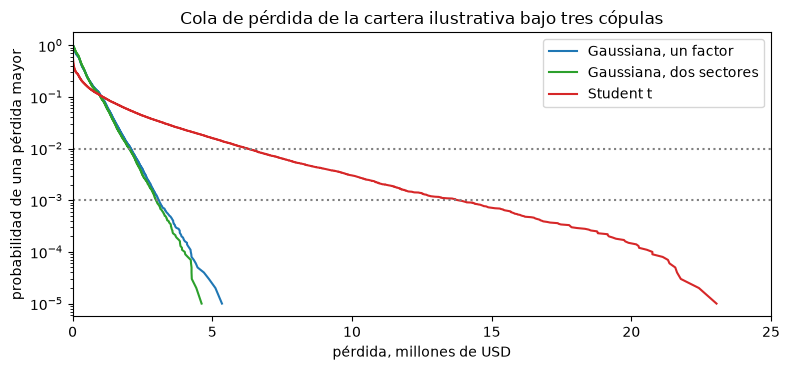

In [7]:
# Dibujar la probabilidad de exceder cada pérdida para las tres muestras en un eje logarítmico
samples = (
    (sample_1f, "Gaussiana, un factor", "tab:blue"),
    (sample_mf, "Gaussiana, dos sectores", "tab:green"),
    (sample_t, "Student t", "tab:red"),
)
fig, ax = plt.subplots(figsize=(8, 3.8))
for sample, label, color in samples:
    ordered = np.sort(sample.losses)
    exceed = 1.0 - np.arange(1, ordered.size + 1) / ordered.size
    keep = exceed > 0
    ax.plot(ordered[keep] / 1e6, exceed[keep], label=label, color=color)
for q in (0.99, 0.999):
    ax.axhline(1 - q, color="gray", linestyle=":")
ax.set_yscale("log")
ax.set_xlim(0, 25)
ax.set_xlabel("pérdida, millones de USD")
ax.set_ylabel("probabilidad de una pérdida mayor")
ax.set_title("Cola de pérdida de la cartera ilustrativa bajo tres cópulas")
ax.legend()
fig.tight_layout()
plt.show()

Cada curva da, para cada pérdida del eje horizontal, la probabilidad de una pérdida mayor, y las dos líneas punteadas marcan los niveles de 1% y 0,1% donde se leen los VaR. Las dos curvas gaussianas corren juntas y la de dos sectores queda algo más abajo, como decía la tabla. La curva t de Student se separa pronto y queda muy a la derecha: en la línea del 0,1% está a más de cuatro veces la pérdida gaussiana. Todas comparten la misma PD marginal de cada nombre, así que toda la diferencia es el comportamiento conjunto de los incumplimientos. La figura no puede decir qué cola es la correcta; eso depende de los grados de libertad, que el caso fija y los datos no estiman.

### Paso 3: el error estándar de Monte Carlo

Un VaR de Monte Carlo es una estimación, y un validador necesita saber cuán precisa es. `mc_standard_errors` del motor divide la muestra en lotes consecutivos (20 por defecto), calcula VaR y ES en cada uno, e informa la desviación estándar de las estimaciones de los lotes sobre $\sqrt{20}$; este estimador es una elección del contrato del motor, la investigación no nombra ninguno. El error debe reducirse como $1/\sqrt S$ con el número de escenarios $S$. La celda siguiente toma los primeros 10.000, 25.000, 50.000 y 100.000 escenarios de la muestra gaussiana e imprime los errores estándar al 99% y al 99,9%.

In [8]:
# Errores estándar de VaR y ES al 99% y al 99,9% para números crecientes de escenarios
from riskvalidation.portfolio.copula import mc_standard_errors

sizes = (10_000, 25_000, 50_000, 100_000)
se_99, se_999, es_99 = [], [], []
for n in sizes:
    v99, e99 = mc_standard_errors(sample_1f.losses[:n], 0.99, 20)
    v999, _ = mc_standard_errors(sample_1f.losses[:n], 0.999, 20)
    se_99.append(v99)
    se_999.append(v999)
    es_99.append(e99)

print(f"{'escenarios':>10s} {'EE VaR 99%':>16s} {'EE ES 99%':>16s} {'EE VaR 99,9%':>18s}")
for n, v, e, w in zip(sizes, se_99, es_99, se_999):
    print(f"{n:10,d} {v:16,.0f} {e:16,.0f} {w:18,.0f}")
print("razón de los errores del VaR 99%, 10,000 a 100,000 escenarios:", round(se_99[0] / se_99[-1], 2))
print("sqrt(10) =", round(math.sqrt(10), 2))
print("razón de los errores del VaR 99,9%:", round(se_999[0] / se_999[-1], 2))
print("escenarios de cola en un lote de 5,000 al 99,9%:", round(5_000 * (1 - 0.999), 1))

escenarios       EE VaR 99%        EE ES 99%       EE VaR 99,9%
    10,000           67,701           62,462             97,473
    25,000           40,518           50,757             79,648
    50,000           24,976           33,882             65,394
   100,000           18,433           24,792             54,340
razón de los errores del VaR 99%, 10,000 a 100,000 escenarios: 3.67
sqrt(10) = 3.16
razón de los errores del VaR 99,9%: 1.79
escenarios de cola en un lote de 5,000 al 99,9%: 5.0


La celda siguiente dibuja el error estándar del VaR contra el número de escenarios en ejes logarítmicos, con la recta que seguiría una ley $1/\sqrt S$.

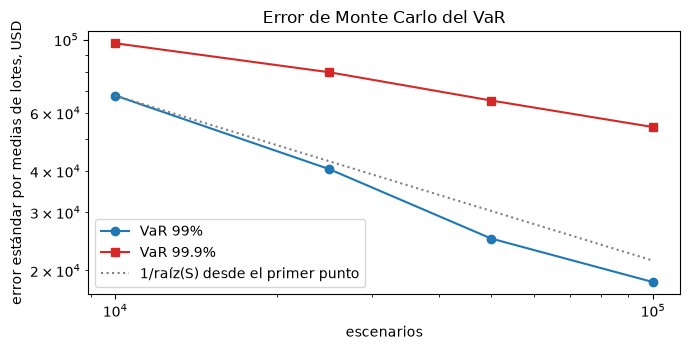

In [9]:
# Dibujar el error estándar del VaR contra el número de escenarios
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.loglog(sizes, se_99, "o-", color="tab:blue", label="VaR 99%")
ax.loglog(sizes, se_999, "s-", color="tab:red", label="VaR 99.9%")
reference = se_99[0] * np.sqrt(sizes[0] / np.array(sizes))
ax.loglog(sizes, reference, ":", color="gray", label="1/raíz(S) desde el primer punto")
ax.set_xlabel("escenarios")
ax.set_ylabel("error estándar por medias de lotes, USD")
ax.set_title("Error de Monte Carlo del VaR")
ax.legend()
fig.tight_layout()
plt.show()

La línea azul, el VaR al 99%, cae casi paralela a la referencia gris: cada aumento de diez veces en los escenarios divide el error por cerca de tres, como dice la ley de la raíz cuadrada. La línea roja, el VaR al 99,9%, es más plana y queda bastante más arriba, porque un lote de 5.000 escenarios tiene solo cinco escenarios de cola y la estimación del cuantil por lote es inestable. El error por medias de lotes en la cola lejana subestima entonces lo que mediría un validador al repetir toda la simulación, y la respuesta correcta es más escenarios o un método de eventos raros como el muestreo por importancia del notebook 05. La figura cubre una semilla y una cartera.

### Paso 4: la convergencia al límite de la cartera grande, y la prueba del motor

Una cartera finita queda sobre el cuantil de la cartera grande por un efecto de granularidad que se desvanece cuando crece el número de nombres. Para una cartera de $N$ nombres idénticos con la PD y la correlación ajustadas, el VaR de Monte Carlo debe converger al `lhp_quantile` cerrado del notebook 01. `mc_convergence` del motor prueba la estimación contra un ancla analítica: el estadístico es $(\text{estimación}-\text{ancla})/\mathrm{ee}$ y su valor p es el valor p normal de dos colas; es una puerta interna de Contraste, verde desde 0,05 y roja bajo 0,01, y solo tiene sentido para una cartera cercana al límite. La celda siguiente simula 50.000 escenarios para cinco tamaños de cartera, de 20 a 5.000 nombres, sobre los mismos 100 millones de USD de exposición, y prueba cada uno contra el ancla.

In [10]:
# Simular carteras de 20 a 5.000 nombres idénticos y probar cada VaR contra el cuantil de la cartera grande
from riskvalidation.validation.portfolio import mc_convergence

anchor = pf.lhp_measures(book["total_ead"], book["lgd_mean"], pd_hat, rho_hat, (0.999,))[0].var
print("VaR de la cartera grande al 99,9%:", f"{anchor:,.0f}")
name_counts = (20, 100, 500, 2000, 5000)
ratios, lights = [], []
print(f"{'nombres':>7s} {'VaR MC':>12s} {'VaR / ancla':>14s} {'p':>9s} luz")
for n_names in name_counts:
    group = {
        "id": "g", "n_names": n_names, "ead_each": book["total_ead"] / n_names, "pd": pd_hat,
        "lgd": book["lgd_mean"], "loading": math.sqrt(rho_hat), "sector": "core",
    }
    identical = pf.portfolio_from_groups([group], book["currency"], book["lgd_gamma"], one_factor=True)
    chunk = max(1000, min(100_000, 150_000_000 // (8 * n_names)))
    run_n = copula.simulate_gaussian(identical, 50_000, 4005, chunk)
    m = pf.measures_from_sample(run_n.losses, (0.999,), pf.expected_loss(identical))[0]
    verdict = mc_convergence(m.var, m.var_se, anchor, "var", model_id="identical-names", segment=f"{n_names}-names")
    ratios.append(m.var / anchor)
    lights.append(verdict.light.value)
    print(f"{n_names:7d} {m.var:12,.0f} {m.var / anchor:14.3f} {verdict.p_value:9.2e} {LIGHTS[verdict.light.value]}")

VaR de la cartera grande al 99,9%: 2,298,833
nombres       VaR MC    VaR / ancla         p luz
     20    6,750,000          2.936  0.00e+00 rojo
    100    3,150,000          1.370  2.35e-19 rojo
    500    2,520,000          1.096  6.06e-08 rojo
   2000    2,340,000          1.018  4.67e-01 verde
   5000    2,286,000          0.994  8.43e-01 verde


La celda siguiente dibuja la razón del VaR de Monte Carlo al VaR de la cartera grande contra el número de nombres, coloreada por la luz de la prueba de convergencia.

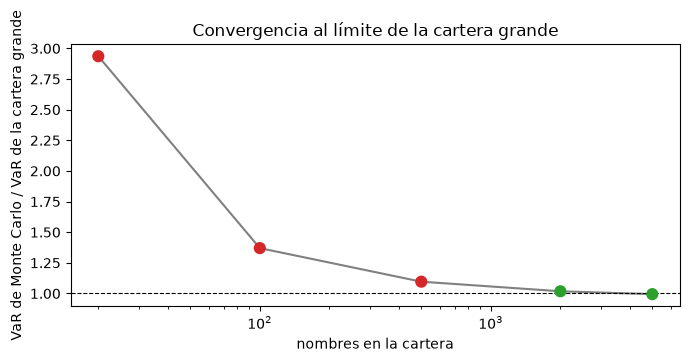

In [11]:
# Dibujar la razón de VaR contra el número de nombres, coloreada por la luz
colors = {"green": "tab:green", "amber": "tab:orange", "red": "tab:red"}
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(name_counts, ratios, "-", color="gray")
ax.scatter(name_counts, ratios, c=[colors[v] for v in lights], s=60, zorder=3)
ax.axhline(1.0, color="black", linestyle="--", linewidth=0.8)
ax.set_xscale("log")
ax.set_xlabel("nombres en la cartera")
ax.set_ylabel("VaR de Monte Carlo / VaR de la cartera grande")
ax.set_title("Convergencia al límite de la cartera grande")
fig.tight_layout()
plt.show()

Los puntos bajan desde casi tres veces el límite con 20 nombres hasta el propio límite con 5.000, y los colores dicen dónde la prueba del motor acepta la comparación: rojo hasta 500 nombres, verde desde 2.000. Una cartera pequeña conserva una parte idiosincrática grande de su riesgo, así que su cuantil queda bastante sobre la forma cerrada, y la prueba se niega con razón a llamarlos iguales. La prueba es una puerta de la comparación, no un veredicto sobre la cópula: dice que solo una cartera de un par de miles de nombres idénticos puede compararse con el límite del notebook 01, y por eso el caso agrega el ajuste por granularidad del notebook 04 para la cartera de 1.120 nombres.

## Resultados

**Respuesta:** una cópula gaussiana de un factor pone el valor en riesgo al 99,9% de la cartera de 1.120 nombres en 3.087.000 USD, con capital de 2.677.279 USD y un error de Monte Carlo de 54.340 USD; dos sectores correlacionados lo bajan a 2.988.000 USD, mientras una cópula t de Student con 5 grados de libertad lo multiplica a 13.815.000 USD, 4,48 veces el gaussiano.

- **La cartera finita necesita una simulación.** En la cartera ilustrativa de 1.120 nombres, la cópula gaussiana de un factor con 100.000 escenarios da un VaR al 99% de 2.088.000 USD y un VaR al 99,9% de 3.087.000 USD, con capital de 1.678.279 y 2.677.279 USD. Ambos quedan sobre el VaR de la cartera grande de 2.298.833 USD al 99,9% del notebook 01, porque la cartera tiene 104 nombres efectivos, no infinitos.
- **Dos sectores bajan la cola, un factor es la elección conservadora.** Con dos factores sectoriales correlacionados en 0,5, el VaR al 99,9% es 2.988.000 USD frente a 3.087.000 USD con un factor. Las cargas son las mismas; lo que cambia es que el núcleo y la periferia ya no caen juntos cada vez. Un validador debe decir qué estructura de dependencia supone la cifra de capital.
- **La cópula t de Student multiplica la cola.** Con 5 grados de libertad y la misma correlación de activos, el VaR al 99% es 6.264.000 USD y el VaR al 99,9% 13.815.000 USD, 3,00 y 4,48 veces los de la cópula gaussiana. La causa se ve con dos nombres: la probabilidad de incumplimiento conjunto es 1,29e-4 bajo la cópula gaussiana (1,55 veces los 8,29e-5 de nombres independientes) y 8,05e-4 bajo la cópula t, 6,26 veces mayor, y las simulaciones del motor, 1,39e-4 y 8,25e-4, concuerdan con la forma cerrada de SciPy dentro de unos dos errores estándar de Monte Carlo. La PD marginal es la misma en ambas; solo difiere el comportamiento conjunto.
- **El error de Monte Carlo se reduce como la raíz de los escenarios, hasta que se acaba la cola.** Al 99% el error estándar del VaR baja de 67.701 a 18.433 USD entre 10.000 y 100.000 escenarios, una razón de 3,67 frente a los 3,16 que predice la raíz cuadrada. Al 99,9% baja solo de 97.473 a 54.340 (una razón de 1,79): un lote de 5.000 escenarios tiene 5 escenarios de cola, muy pocos para que la estimación por lote del cuantil 99,9% sea estable. Un error de medias por lotes en la cola lejana es una cota inferior de la incertidumbre real, por eso un validador lee el error estándar junto a cada cifra de capital de Monte Carlo.
- **La cartera finita converge al límite de la cartera grande cuando crece.** El VaR de Monte Carlo sobre el VaR de la cartera grande es 2,94 con 20 nombres, 1,37 con 100, 1,10 con 500, 1,02 con 2.000 y 0,99 con 5.000. La prueba de convergencia es roja con 20, 100 y 500 nombres y verde con 2.000 y 5.000 (p = 0,47 y 0,84). La prueba no es un veredicto sobre el modelo: dice que la cartera es demasiado pequeña para compararla con la forma cerrada, que es exactamente por qué el caso informa el ajuste por granularidad aparte (notebook 04).

Lo que este notebook no muestra: la alternativa actuarial a la cópula (notebook 04), cómo se reparte el capital entre los grupos (notebook 05), ni qué cópula debe usar un banco. La cartera es ilustrativa y los grados de libertad de la t de Student son un supuesto del caso, no una estimación.

## Resumen

- Una cartera finita tiene una pérdida aleatoria incluso dada la economía; la cópula gaussiana (`simulate_gaussian`) y la cópula t de Student (`simulate_student_t`) la simulan, y `measures_from_sample` devuelve VaR, ES y capital con errores estándar por medias de lotes.
- La estructura de dependencia mueve el capital: dos sectores correlacionados bajan la cola respecto de un factor, y la cópula t eleva el VaR al 99,9% a varias veces el gaussiano con la misma correlación de activos, porque tiene dependencia de cola.
- Una cifra de capital de Monte Carlo está incompleta sin su error estándar, y un error de medias por lotes en la cola lejana necesita muchos escenarios por lote.
- `mc_convergence` compara un VaR de Monte Carlo con el cuantil de la cartera grande, y reprueba las carteras demasiado pequeñas para la comparación.

**Qué probar a continuación.** Cambia los grados de libertad `nu` a 10 y a 30 y mira cómo el VaR t de Student se acerca al gaussiano. Luego abre el notebook 04, donde la misma cartera se calcula sin simulación con CreditRisk+ y el ajuste por granularidad.

## Referencias

- Li, D. X. (2000), On default correlation: a copula function approach, Journal of Fixed Income 9(4):43-54. https://doi.org/10.3905/jfi.2000.319253
- Frey, R. y McNeil, A. J. (2003), Dependent defaults in models of portfolio credit risk, Journal of Risk 6(1):59-92. https://doi.org/10.21314/jor.2003.089
- Demarta, S. y McNeil, A. J. (2005), The t copula and related copulas, International Statistical Review 73(1):111-129. https://doi.org/10.1111/j.1751-5823.2005.tb00254.x
- Gordy, M. B. (2003), A risk-factor model foundation for ratings-based bank capital rules, Journal of Financial Intermediation 12(3):199-232. https://doi.org/10.1016/S1042-9573(03)00040-8
- Acerbi, C. y Tasche, D. (2002), On the coherence of expected shortfall, Journal of Banking and Finance 26(7):1487-1503. https://doi.org/10.1016/S0378-4266(02)00283-2
- Board of Governors of the Federal Reserve System, Charge-off and delinquency rates on loans and leases at commercial banks, table chgallsa (public domain; licence class mirror-allowed). https://www.federalreserve.gov/releases/chargeoff/chgallsa.htm
- Persisted research dossier 04 of this product (credit-risk models, state of the art), sections H.1 and H.3 (the loss measures and the copula models).
- The engine's contract for these functions: `docs/contracts/engine/` of this repository.